# 多叉树规则挖掘与三数据集业务报告

以真实放款数据 `hscredit_yyp.xlsx` 为例，用 **FPD** 挖掘客群规则，再由业务人员调整节点，最终输出树图、完整规则清单及训练集／验证集／测试集 Excel 报告。

流程：自动建树 → 节点剪枝 → 节点自动重选特征 → 指定特征自动找切点 → 指定特征和阈值 → 定稿 → 导出全部规则 → 三数据集评估与 Excel。

全部建树与节点调整只使用训练集。验证集用于复核，测试集在定稿后统一评估。本例采用分层随机拆分，不将测试集称为时间外样本。阈值仅用于演示人工调整流程，可根据业务政策替换。

与手工二叉树共用 `get_rule_table()`、`get_rules()` 和 `report(..., save=...)` 的调用方式。Excel 由 `report` 自带功能生成，Notebook 不组装工作簿。请从头顺序运行；修改前面的参数后，从该步骤继续运行后续单元格。

In [1]:
from pathlib import Path
from copy import deepcopy
import sys

ROOT = Path.cwd() if (Path.cwd() / "hscredit").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink, Image as NotebookImage
from sklearn.model_selection import train_test_split
from hscredit import MultiwayTreeExtractor, plot_tree
from hscredit.utils import style_rule_table

data_path = ROOT / "examples" / "hscredit_yyp.xlsx"
output_dir = ROOT / "examples" / "model_report" / "multiway_tree"
output_dir.mkdir(parents=True, exist_ok=True)

target = "FPD"
features = ["衡枢鉴真分老客版", "近六个月非银多头机构数", "青云24", "商品类别"]
overdue = ["MOB1"]
dpds = [7, 3, 0]
amount = "放款金额"
random_state = 42

## 1. 准备训练集、验证集与测试集

按 FPD 分层随机拆分为 60%／20%／20%，保留原始索引用于核对样本。特征缺失交给树的现有路由处理，不在示例中填补或人为注入缺失值。放款金额单位为元。

FPD 必须为有效的 0/1 标签；本例的 MOB1 必须非负且完整，避免将未成熟或未知的逾期结果记为正常。

In [2]:
data = pd.read_excel(data_path)
required = features + [target, *overdue, amount, "放款时间"]
missing_columns = sorted(set(required) - set(data.columns))
if missing_columns:
    raise ValueError(f"数据缺少字段：{missing_columns}")
if not data[target].isin([0, 1]).all():
    raise ValueError("FPD 必须全部为有效的 0/1 标签，请先确认样本表现期。")
if not data[overdue].ge(0).all().all():
    raise ValueError("MOB1 含缺失或负值，请先确认逾期表现期和标签。")

train, holdout = train_test_split(
    data, test_size=0.4, random_state=random_state, stratify=data[target]
)
valid, test = train_test_split(
    holdout, test_size=0.5, random_state=random_state, stratify=holdout[target]
)
datasets = {"训练集": train, "验证集": valid, "测试集": test}
sample_summary = pd.DataFrame([
    {
        "数据集": name, "样本总数": len(frame), "坏样本数": int(frame[target].sum()),
        "FPD坏样本率": frame[target].mean(), "放款金额（元）": frame[amount].sum(),
        "最早放款日期": frame["放款时间"].min(), "最晚放款日期": frame["放款时间"].max(),
    }
    for name, frame in datasets.items()
])
display(sample_summary)

,数据集,样本总数,坏样本数,FPD坏样本率,放款金额（元）,最早放款日期,最晚放款日期
0,训练集,582,82,0.1409,2410385,2025-11-06,2026-02-25
1,验证集,194,27,0.1392,861451,2025-11-08,2026-02-25
2,测试集,194,27,0.1392,815367,2025-11-08,2026-02-25


## 2. 从训练集自动生成多叉树

使用 Gini 准则自动选择特征与分裂点，每个节点最多四个分支、树深最多两层、普通叶节点至少 25 条训练样本。`max_branches=4` 是上限，不要求每个节点都分成四支。

保留自动树作为对照，后续编辑在其副本上进行。

,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,否,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,5,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (-inf, 547] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((青云24 <= 547.0) & (青云24.notna())) | (青云24.isna())),是,否,74,12.71%,59,11.80%,15,18.29%,20.27%,1.44,6.39%,50.26%,78.35%,20.27%,18.29%,19.23%
6,6,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (547, 579]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 547.0) & (青云24 <= 579.0) & (青云24.notna())),是,否,73,12.54%,67,13.40%,6,7.32%,8.22%,0.58,-5.98%,-47.64%,75.43%,8.22%,7.32%,7.74%
7,7,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (579, 595]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 579.0) & (青云24 <= 595.0) & (青云24.notna())),是,否,36,6.19%,30,6.00%,6,7.32%,16.67%,1.18,1.21%,19.50%,81.79%,16.67%,7.32%,10.17%
8,8,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (595, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 595.0) & (青云24.notna())),是,否,253,43.47%,227,45.40%,26,31.71%,10.28%,0.73,-20.81%,-47.87%,51.37%,10.28%,31.71%,15.52%


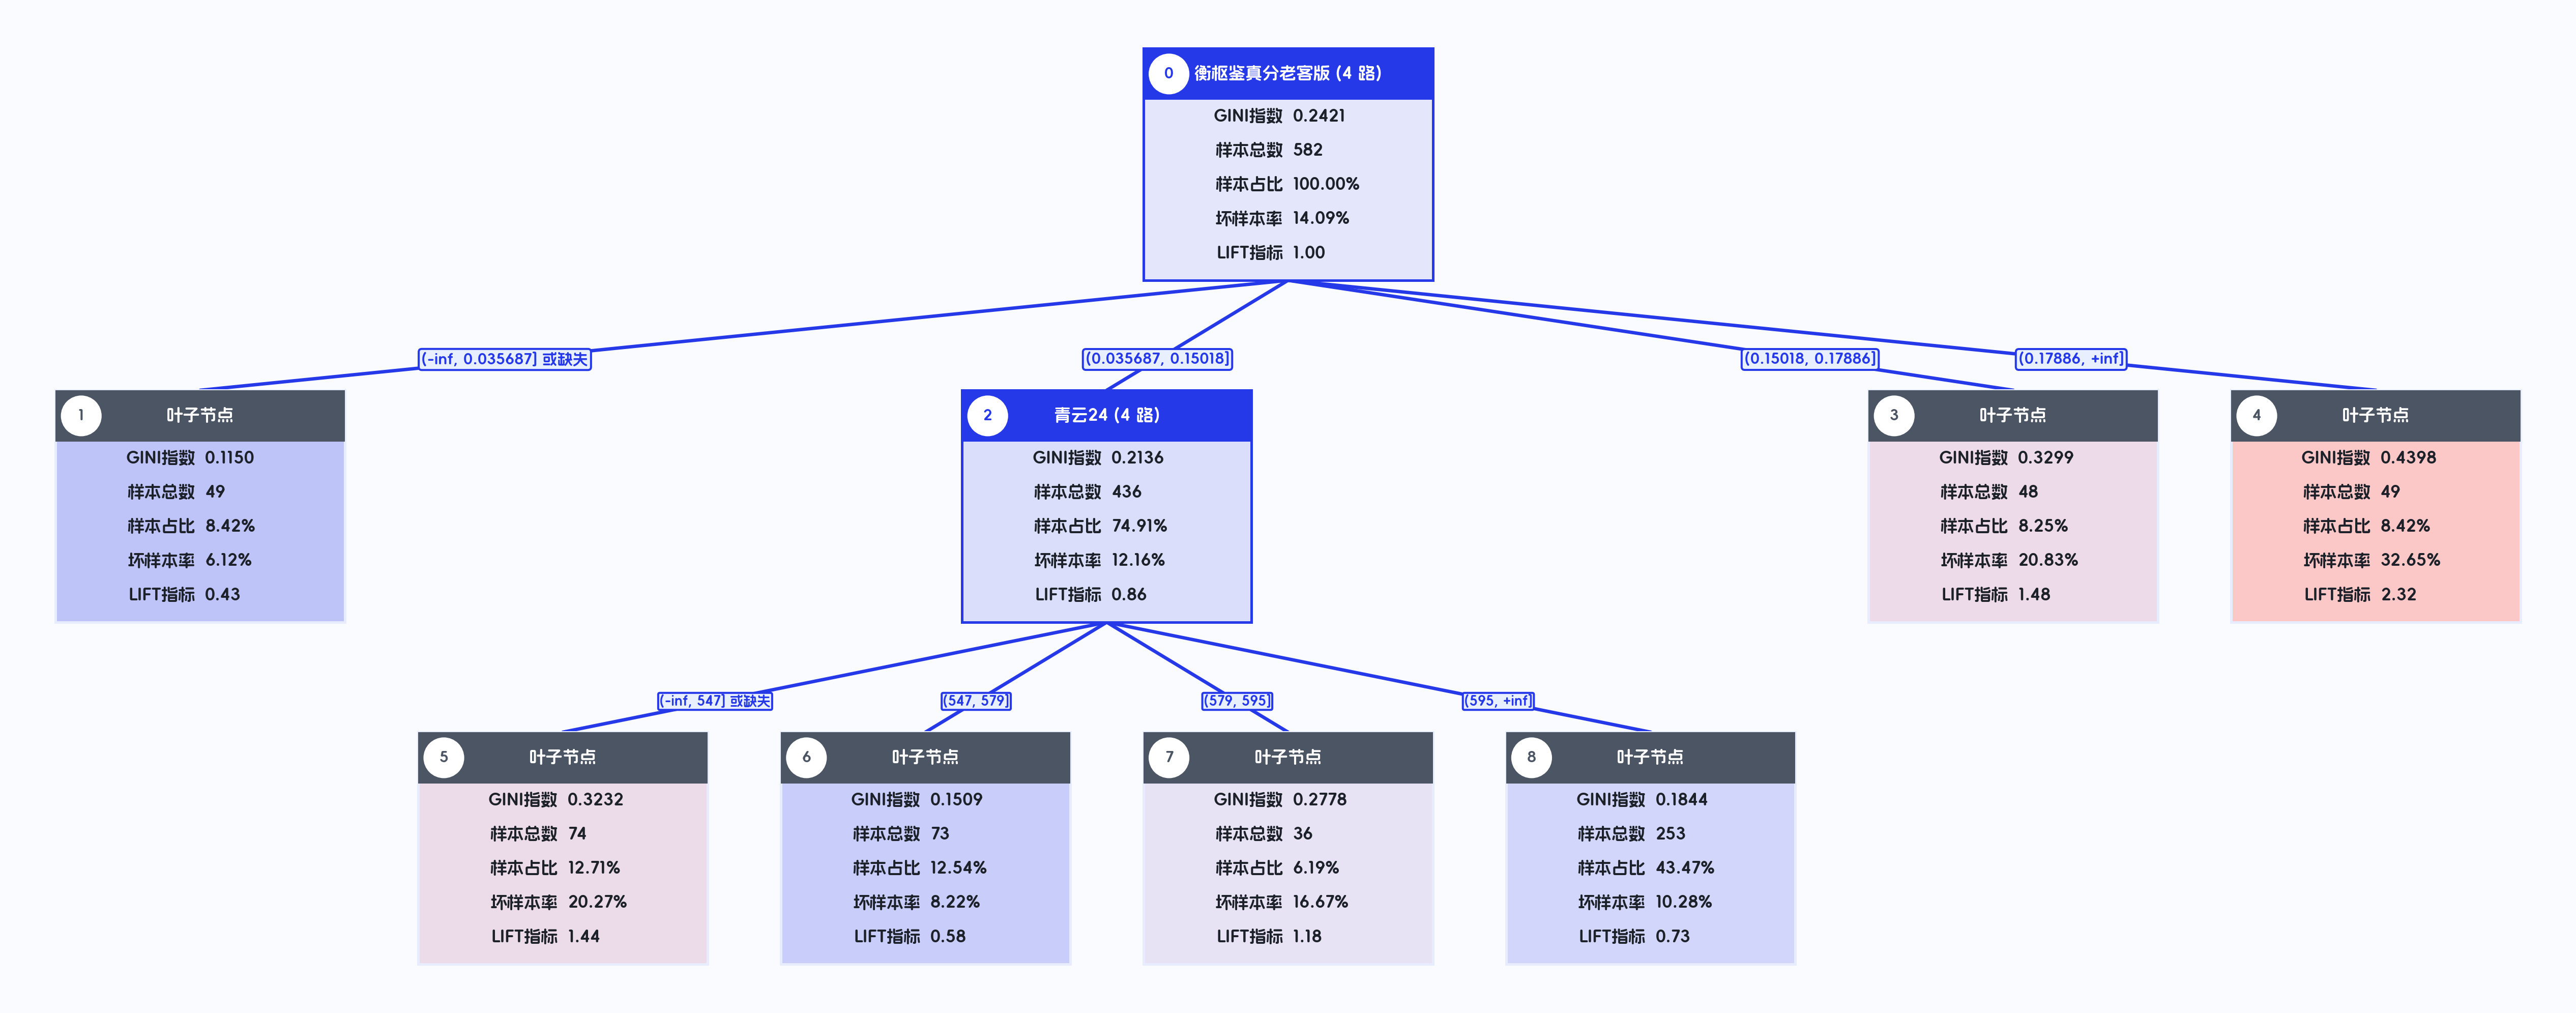

In [3]:
auto_tree = MultiwayTreeExtractor(
    target=target, features=features,
    criterion="gini", max_branches=4, max_depth=2,
    min_samples_split=50, min_samples_leaf=25, n_jobs=1,
).fit(train)

display(style_rule_table(auto_tree.get_rule_table()))
fig = plot_tree(auto_tree, save=str(output_dir / "01_自动生成多叉树.png"))
display(NotebookImage(filename=str(output_dir / "01_自动生成多叉树.png")))
plt.close(fig)
tree = deepcopy(auto_tree)

## 3. 选择节点并剪枝

先从节点表确认编号及对应客群。本例选取训练样本最多的非根内部节点，删除它的全部后代，让该节点先成为叶子。可把 `edit_node` 改成表中其他可分裂节点的编号。

`prune` 保留该节点及其中的样本，不会把客群从树中删除。后续三种分裂方式都作用于这个节点，便于比较同一客群的调整结果。

,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,...,类别_1样本数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比
2,2,0,1,否,青云24,"[547.0, 579.0, 595.0]",[],"[5, 6, 7, 8]",0,否,...,53,0.7491,383,0.7660,53,0.6463,0.1216,0.8628,-0.4098,-0.5470


本次调整节点：2


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),是,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%


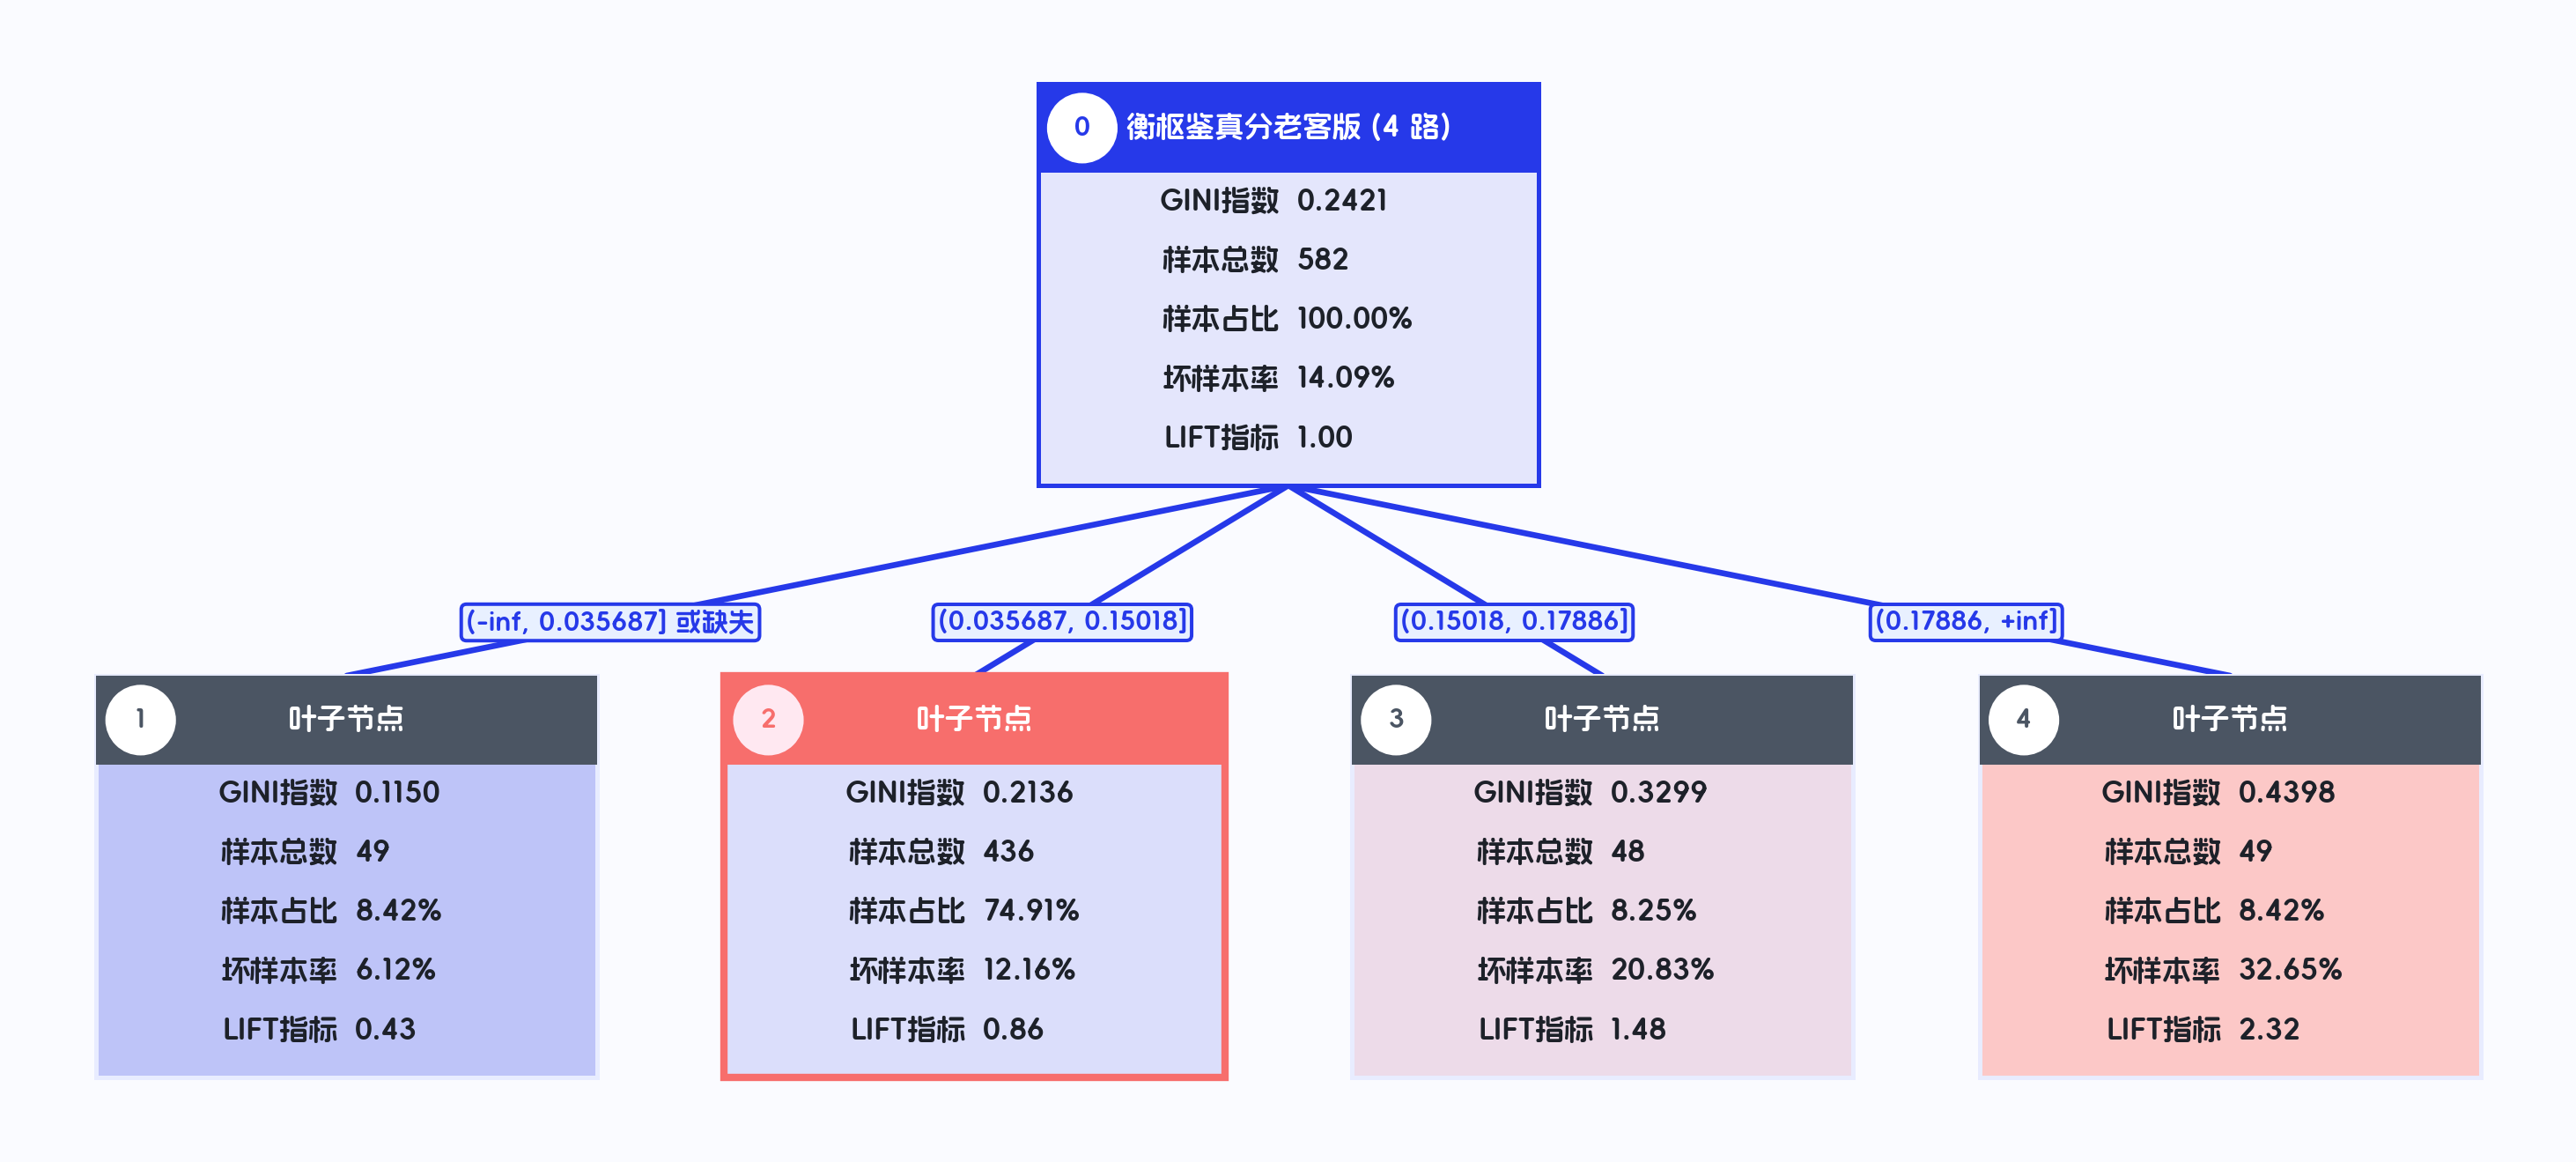

In [4]:
node_table = tree.get_node_table()
editable_nodes = node_table.loc[
    (node_table["深度"] > 0) & (node_table["是否叶子"] == "否")
].sort_values("样本总数", ascending=False)
if editable_nodes.empty:
    raise ValueError("当前自动树没有非根内部节点，请调整建树参数或样本后重新运行。")
edit_node = int(editable_nodes.iloc[0]["节点编号"])
display(editable_nodes)
print(f"本次调整节点：{edit_node}")

tree.prune(node=edit_node)
display(style_rule_table(tree.get_rule_table()))
fig = plot_tree(tree, save=str(output_dir / "02_节点剪枝.png"))
display(NotebookImage(filename=str(output_dir / "02_节点剪枝.png")))
plt.close(fig)

## 4. 控制该节点自动选择特征重新分裂

先查看该客群的候选特征和最优切点。调用 `manual_split(node=edit_node)`，不传特征和阈值，由现有搜索逻辑选择最佳候选。

这是人工要求该节点重新分裂：仍满足候选样本约束，但不受自动生长的显著性／增益门槛限制。`grow=False` 只执行当前一次分裂。相同样本与参数可能选回原方案。

,分裂特征,切分点,类别分组,分支数,缺失分支,缺失独立分支,卡方值,P值,调整后P值,分裂增益,分裂价值
0,青云24,"[547.0, 579.0, 595.0]",[],4,0,否,7.1450,0.0674,1.0000,0.0035,0.0035
1,商品类别,[],"[[珠宝首饰, 电脑数码], [礼包], [手机通讯, 智能设备, 家用电器]]",3,0,否,6.3906,0.0410,0.1229,0.0031,0.0031
2,衡枢鉴真分老客版,"[0.07223049589753014, 0.0804030403674141, 0.13466372065853904]",[],4,0,否,5.2828,0.1522,1.0000,0.0026,0.0026
3,近六个月非银多头机构数,"[64.0, 66.0, 73.0]",[],4,0,否,4.5529,0.2076,1.0000,0.0022,0.0022


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,9,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (-inf, 547] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((青云24 <= 547.0) & (青云24.notna())) | (青云24.isna())),是,是,74,12.71%,59,11.80%,15,18.29%,20.27%,1.44,6.39%,50.26%,78.35%,20.27%,18.29%,19.23%
6,10,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (547, 579]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 547.0) & (青云24 <= 579.0) & (青云24.notna())),是,是,73,12.54%,67,13.40%,6,7.32%,8.22%,0.58,-5.98%,-47.64%,75.43%,8.22%,7.32%,7.74%
7,11,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (579, 595]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 579.0) & (青云24 <= 595.0) & (青云24.notna())),是,是,36,6.19%,30,6.00%,6,7.32%,16.67%,1.18,1.21%,19.50%,81.79%,16.67%,7.32%,10.17%
8,12,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 青云24: (595, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((青云24 > 595.0) & (青云24.notna())),是,是,253,43.47%,227,45.40%,26,31.71%,10.28%,0.73,-20.81%,-47.87%,51.37%,10.28%,31.71%,15.52%


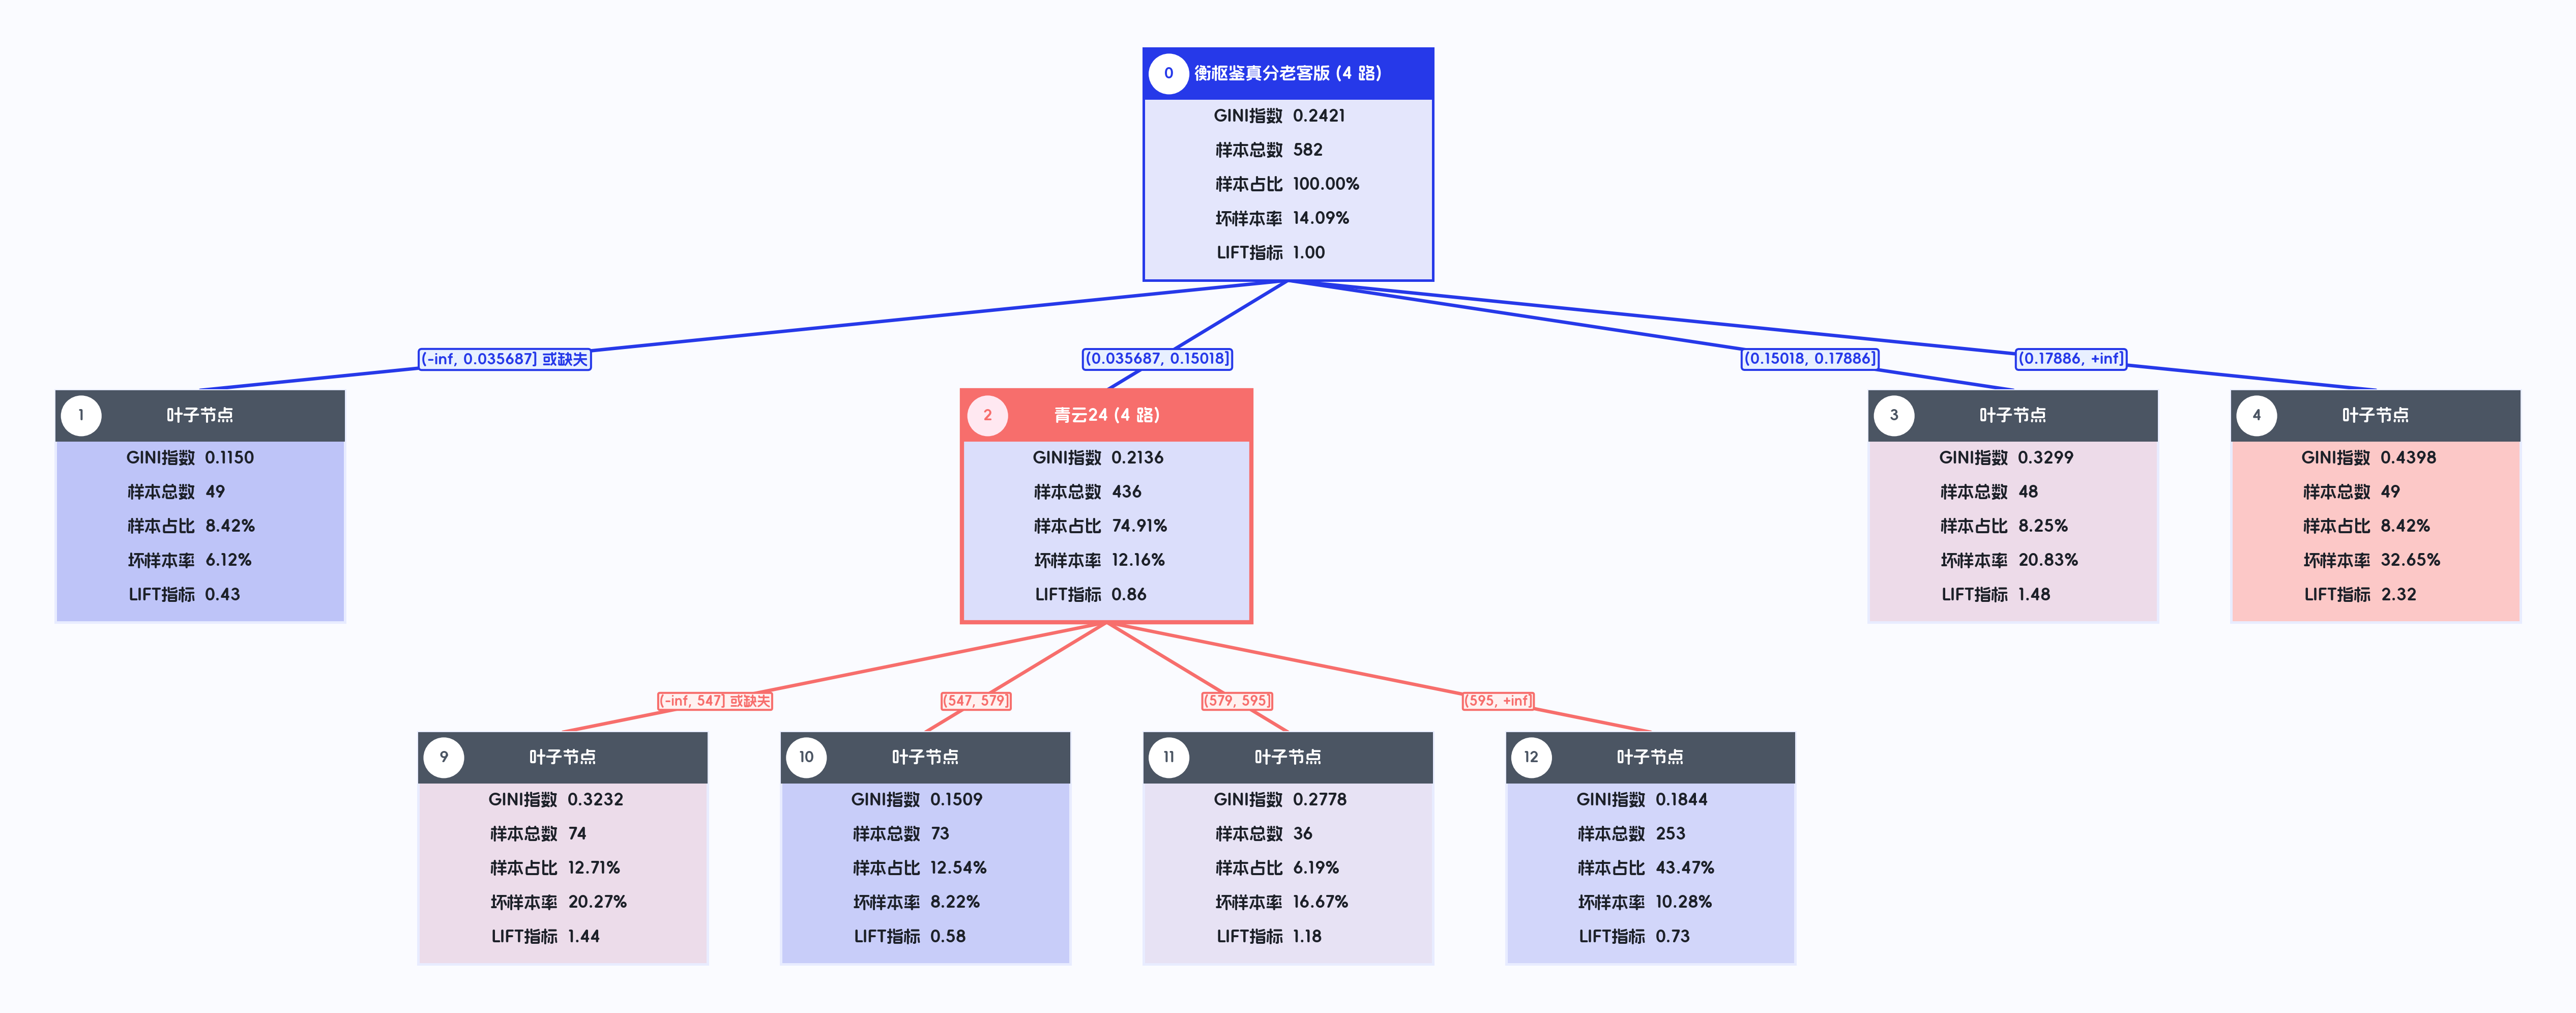

In [5]:
display(tree.get_split_candidates(node=edit_node))
tree.manual_split(node=edit_node, grow=False)
display(style_rule_table(tree.get_rule_table()))
fig = plot_tree(tree, save=str(output_dir / "03_节点自动重选特征.png"))
display(NotebookImage(filename=str(output_dir / "03_节点自动重选特征.png")))
plt.close(fig)

## 5. 指定节点使用某个特征，自动寻找切点

假设业务需要用多头机构数继续区分这批客群，固定 `feature`，切点仍由训练样本自动确定。此操作替换该节点刚生成的后代，根节点和其他子树保留。

,分裂特征,切分点,类别分组,分支数,缺失分支,缺失独立分支,卡方值,P值,调整后P值,分裂增益,分裂价值
3,近六个月非银多头机构数,"[64.0, 66.0, 73.0]",[],4,0,否,4.5529,0.2076,1.0000,0.0022,0.0022


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,13,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 64] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 64.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,270,46.39%,235,47.00%,35,42.68%,12.96%,0.92,-6.92%,-14.91%,51.55%,12.96%,42.68%,19.89%
6,14,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (64, 66]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 64.0) & (近六个月非银多头机构数 <= 66.0) & (近六个月非银多头机构数.notna())),是,是,26,4.47%,26,5.20%,0,0.00%,0.00%,0.00,-4.68%,-104.68%,81.44%,0.00%,0.00%,0.00%
7,15,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (66, 73]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 66.0) & (近六个月非银多头机构数 <= 73.0) & (近六个月非银多头机构数.notna())),是,是,75,12.89%,67,13.40%,8,9.76%,10.67%,0.76,-3.59%,-27.89%,75.77%,10.67%,9.76%,10.19%
8,16,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (73, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 73.0) & (近六个月非银多头机构数.notna())),是,是,65,11.17%,55,11.00%,10,12.20%,15.38%,1.09,1.16%,10.35%,78.18%,15.38%,12.20%,13.61%


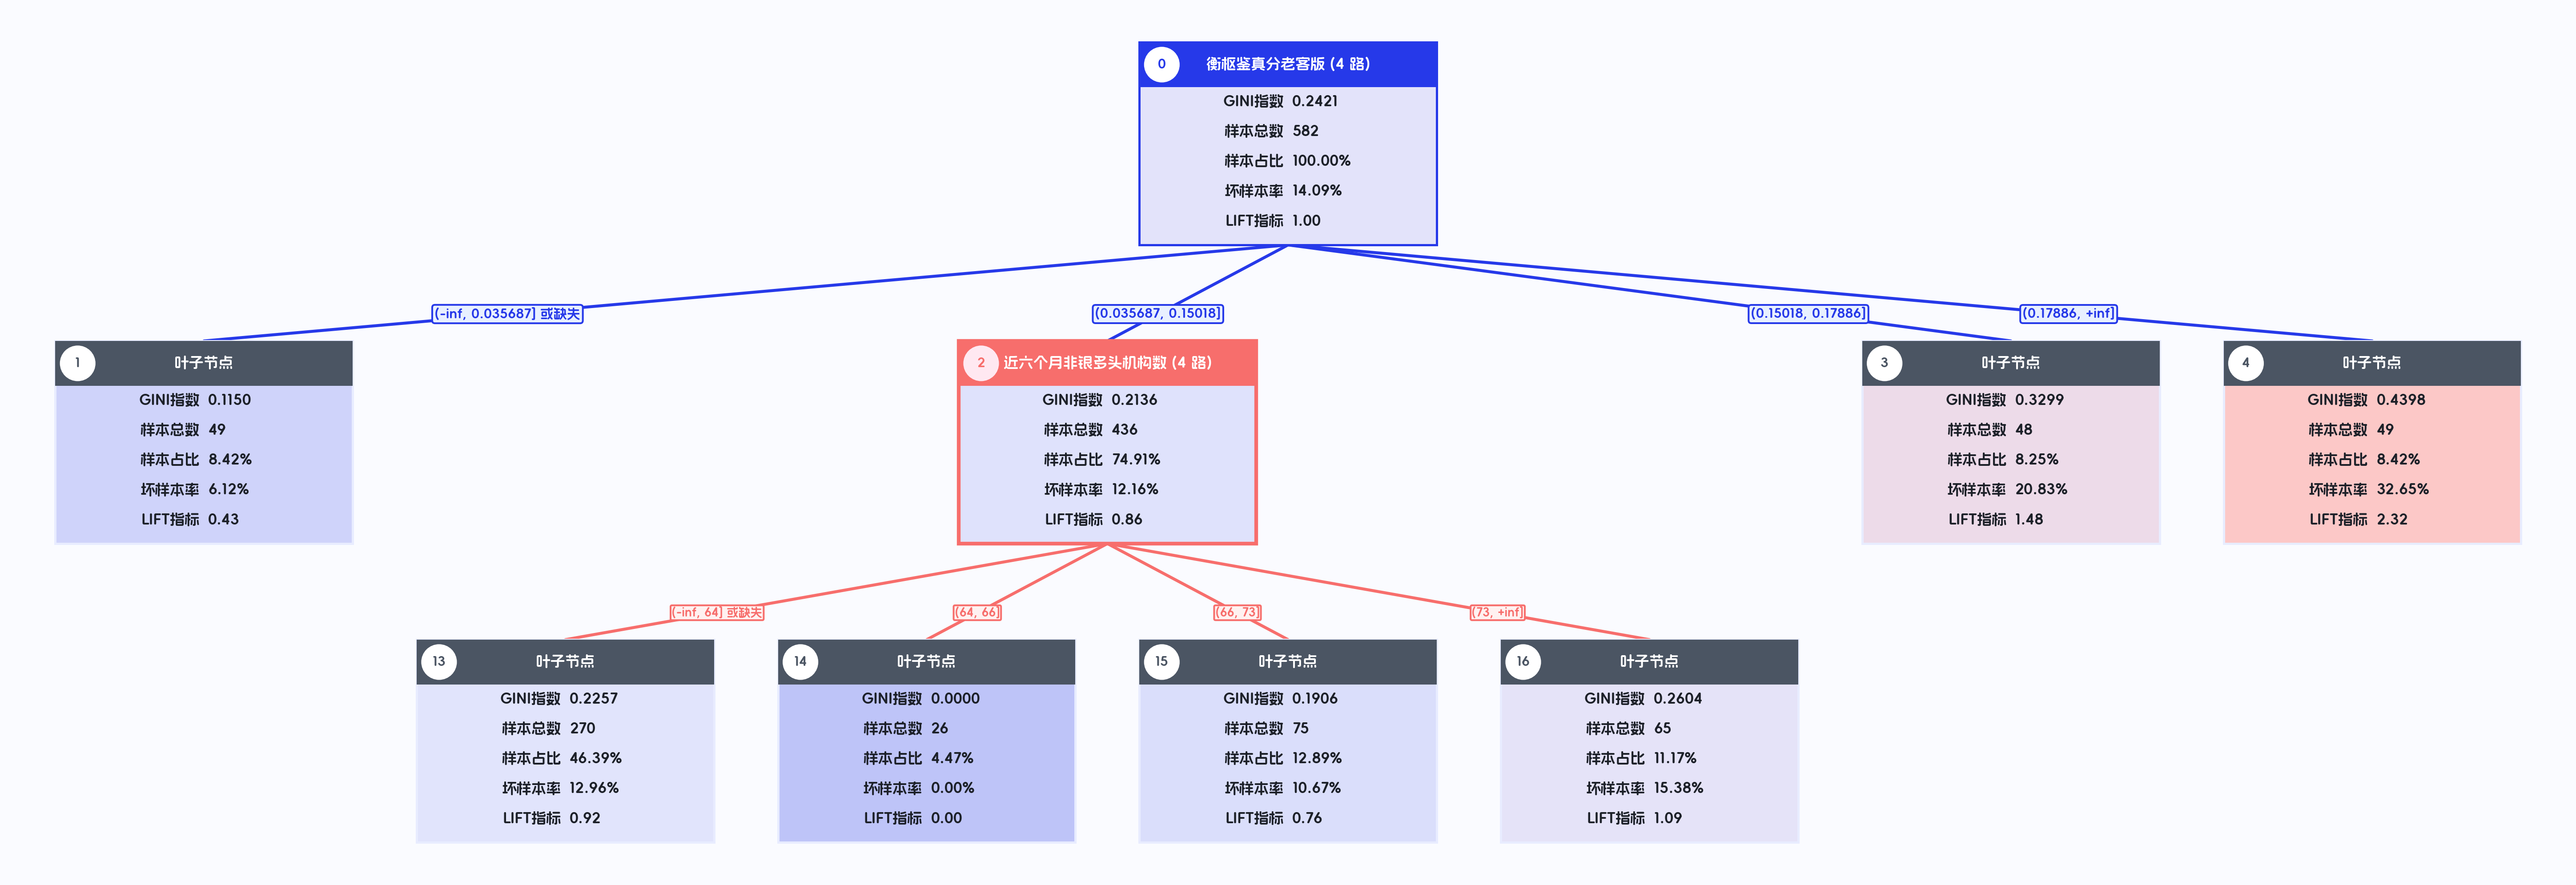

In [6]:
manual_feature = "近六个月非银多头机构数"
feature_candidates = tree.get_split_candidates(node=edit_node)
display(feature_candidates.loc[feature_candidates["分裂特征"] == manual_feature])

tree.manual_split(node=edit_node, feature=manual_feature, grow=False)
display(style_rule_table(tree.get_rule_table()))
fig = plot_tree(tree, save=str(output_dir / "04_指定特征自动切分.png"))
display(NotebookImage(filename=str(output_dir / "04_指定特征自动切分.png")))
plt.close(fig)

## 6. 指定节点、特征和业务阈值

将多头机构数按 **50／65／75** 划分为四档：`≤50`、`(50,65]`、`(65,75]`、`>75`。这些是可编辑的演示阈值，不是根据验证集或测试集反推的结果。

等于阈值的值归入左侧区间。示例明确把未来缺失值合并到第 0 个分支。人工阈值可生成小样本甚至空分支，定稿前需查看节点样本量。

,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,17,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,81,13.92%,70,14.00%,11,13.41%,13.58%,0.96,-0.58%,-4.20%,75.77%,13.58%,13.41%,13.50%
6,18,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非银多头机构数 <= 65.0) & (近六个月非银多头机构数.notna())),是,是,202,34.71%,178,35.60%,24,29.27%,11.88%,0.84,-8.33%,-24.00%,59.45%,11.88%,29.27%,16.90%
7,19,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (65, 75]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 65.0) & (近六个月非银多头机构数 <= 75.0) & (近六个月非银多头机构数.notna())),是,是,106,18.21%,97,19.40%,9,10.98%,8.49%,0.60,-8.85%,-48.59%,70.79%,8.49%,10.98%,9.57%
8,20,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (75, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 75.0) & (近六个月非银多头机构数.notna())),是,是,47,8.08%,38,7.60%,9,10.98%,19.15%,1.36,3.15%,39.07%,80.93%,19.15%,10.98%,13.95%


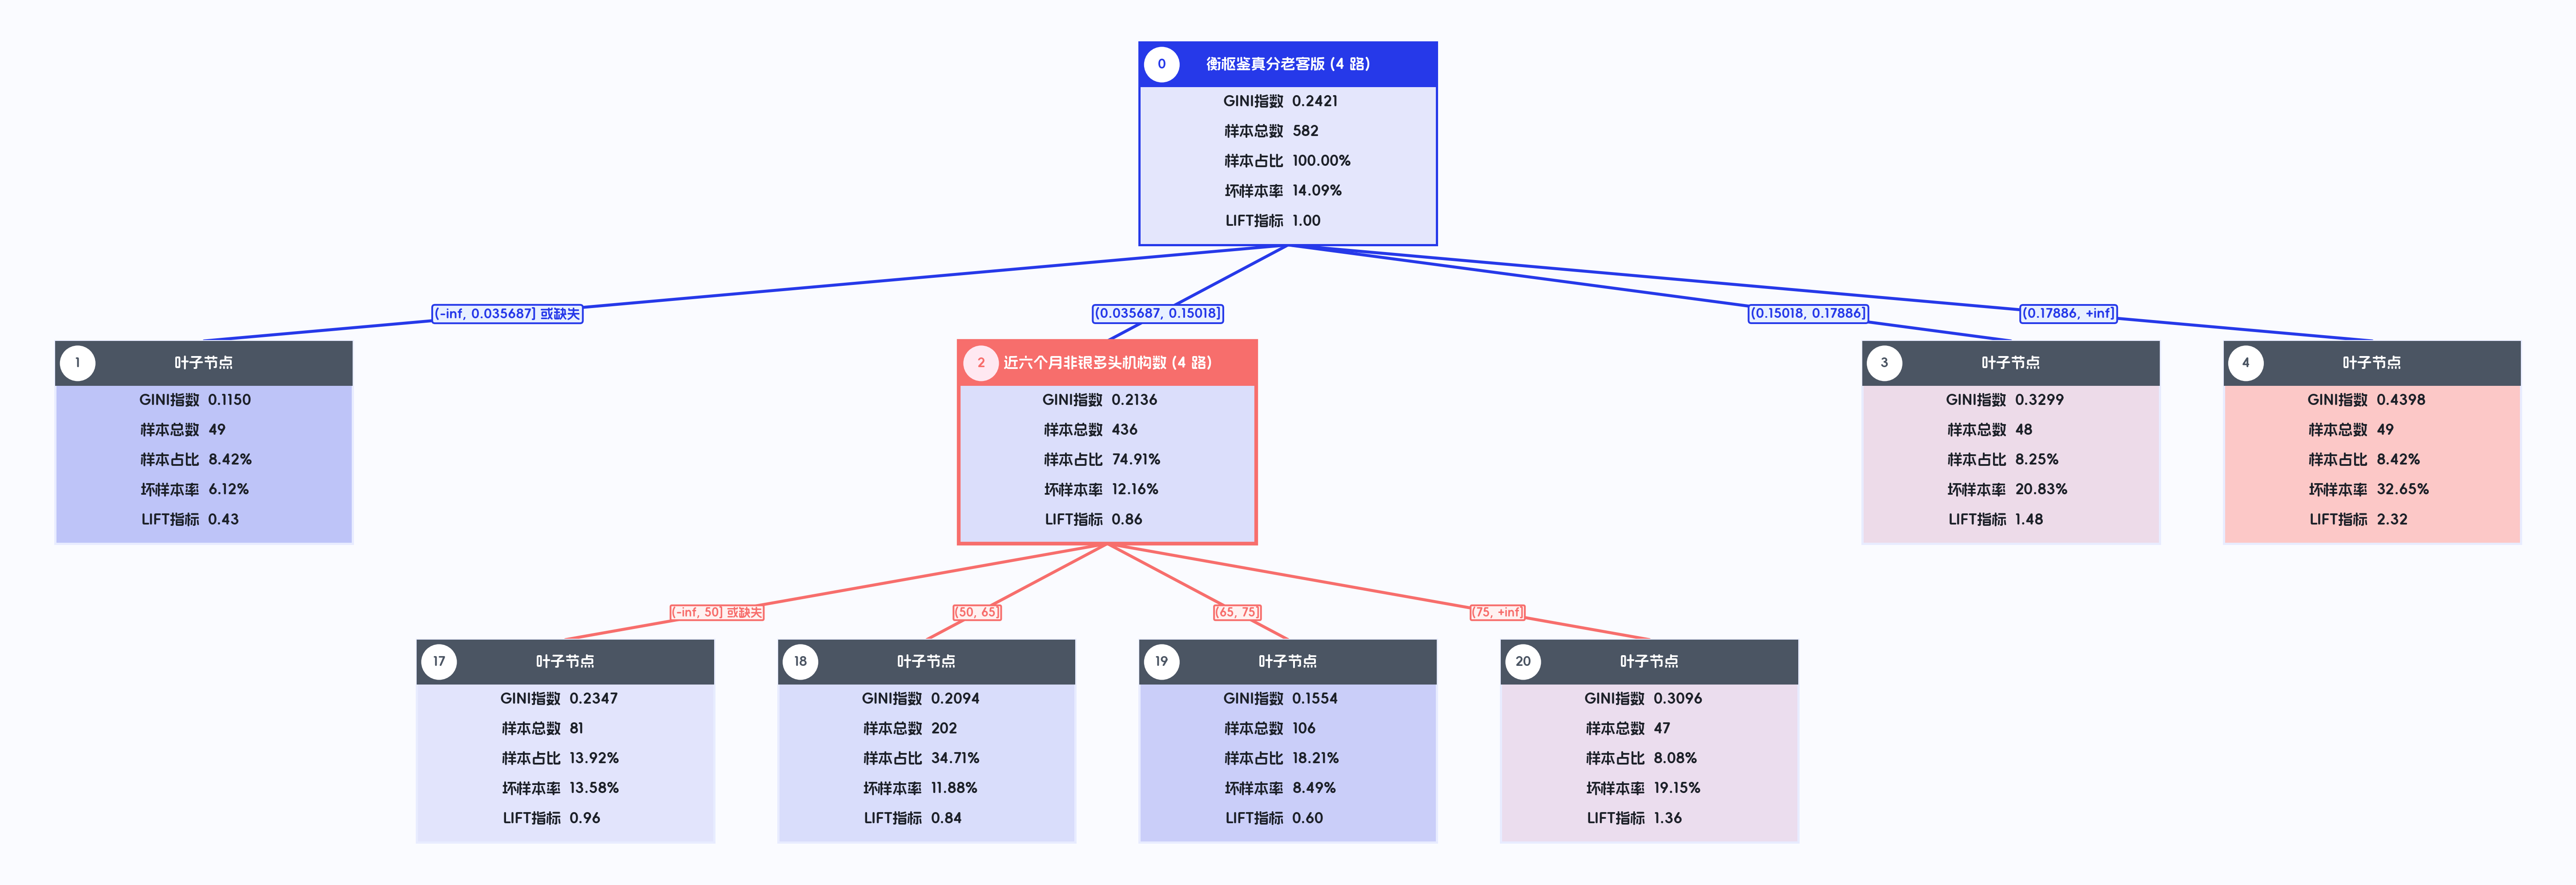

In [7]:
business_thresholds = [50, 65, 75]
tree.manual_split(
    node=edit_node, feature=manual_feature,
    thresholds=business_thresholds, missing_branch=0, grow=False,
)
display(style_rule_table(tree.get_rule_table()))
fig = plot_tree(tree, save=str(output_dir / "05_指定业务阈值.png"))
display(NotebookImage(filename=str(output_dir / "05_指定业务阈值.png")))
plt.close(fig)

## 7. 定稿并展示最终树

编辑后子节点会获得新编号，不能继续使用已删除后代的旧编号。以此处重新取得的节点表为准。

保存最终树供后续复用；保存文件包含训练数据，只在可信环境中保存和加载。

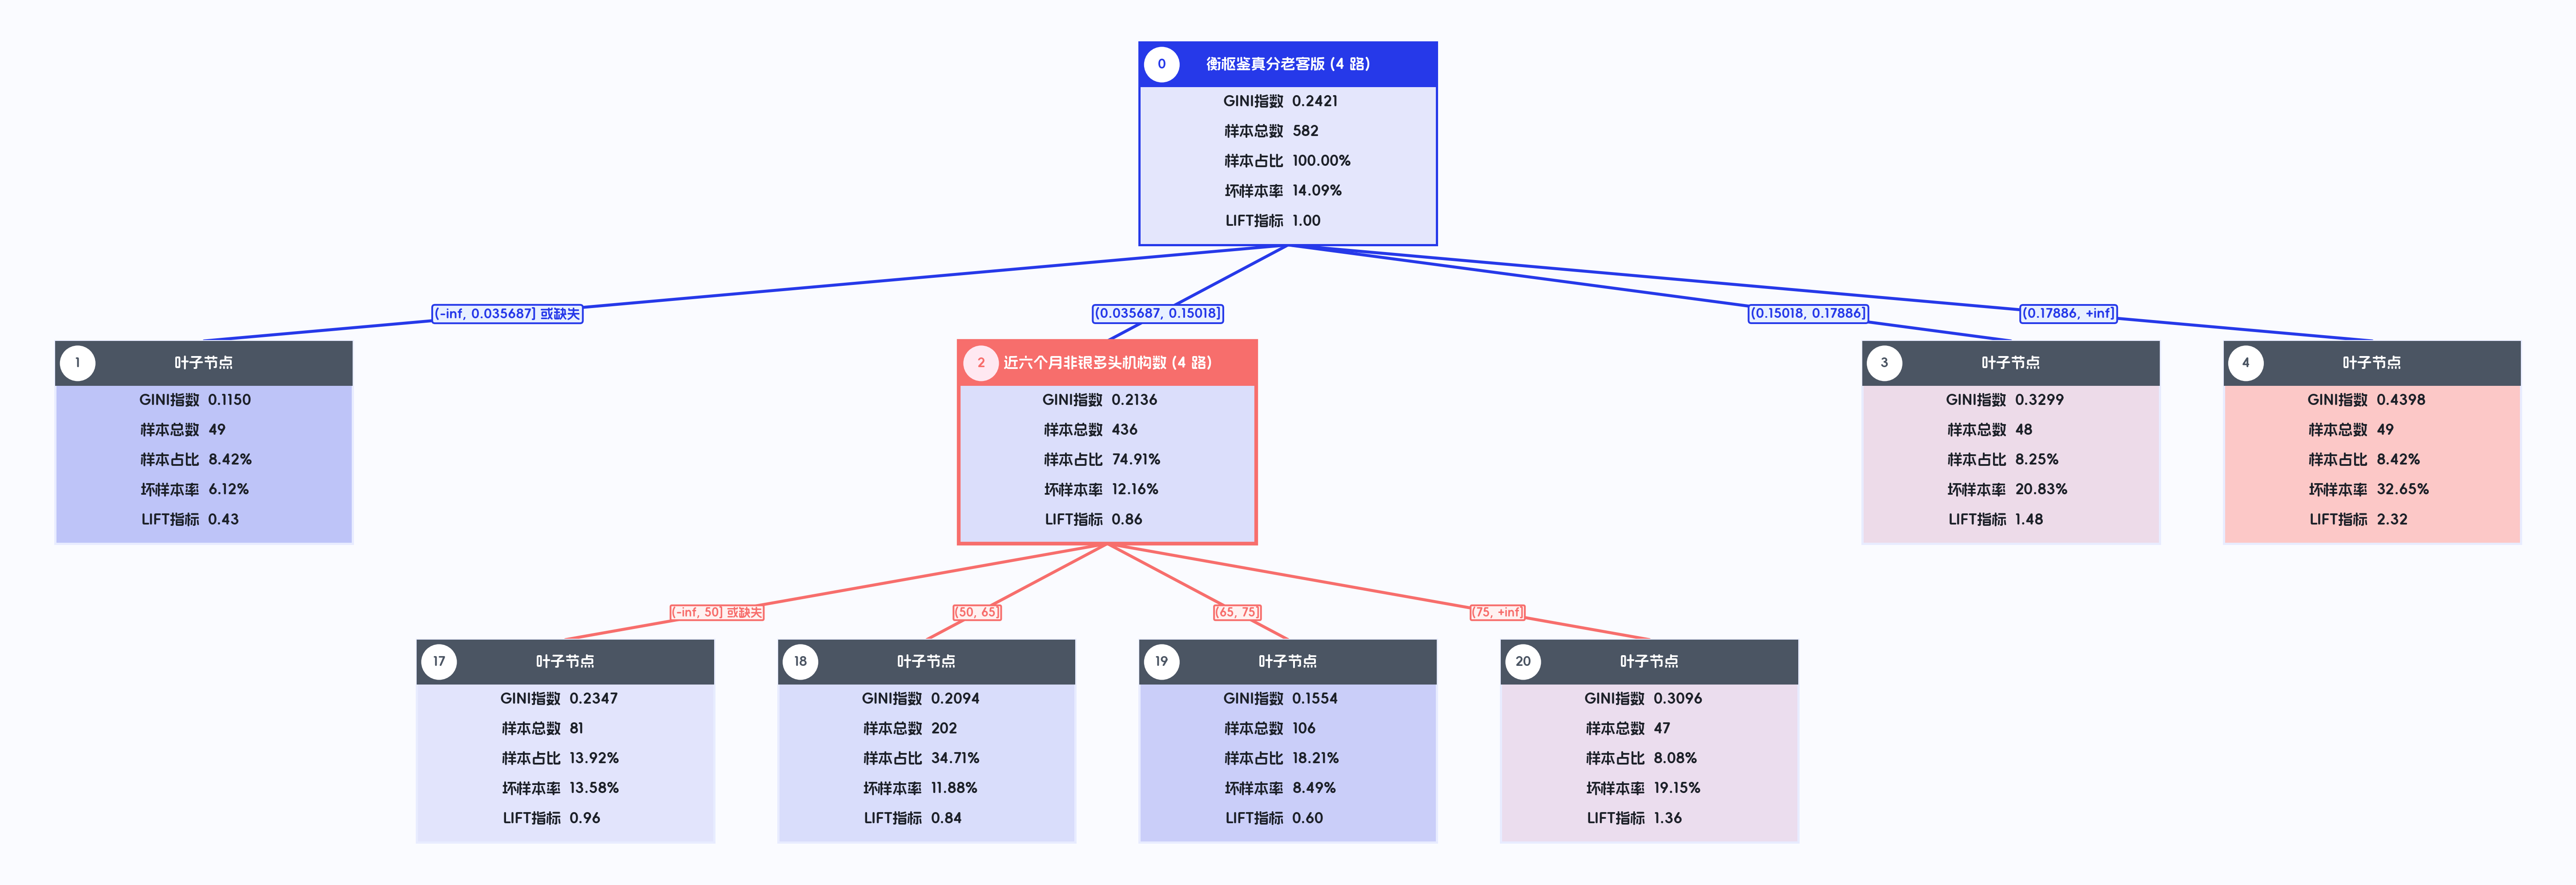

In [8]:
final_tree = deepcopy(tree)
final_plot_path = output_dir / "06_最终多叉树.png"
fig = plot_tree(final_tree, save=str(final_plot_path))
display(NotebookImage(filename=str(final_plot_path)))
plt.close(fig)
model_path = final_tree.save(output_dir / "最终多叉树.pkl")

## 8. 与手工二叉树一致地输出规则信息

`get_rule_table()` 返回全树规则效果，包括根节点、内部节点和叶节点，含样本数、坏率、LIFT、坏账改善与风险拒绝比。`get_rules()` 默认返回叶节点的 `Rule` 对象；`get_rules(leaf_only=False)` 返回全部节点。

完整路径存在父子重叠，不能直接相加样本数。将全部叶节点做 OR 会命中所有样本，并不构成拒绝策略。

In [9]:
display(style_rule_table(final_tree.get_rule_table()))
all_rules = final_tree.get_rules(leaf_only=False)
for rule in all_rules:
    print(f"{rule.name}：{rule.description}\n{rule.expr}\n")
leaf_rules = final_tree.get_rules()
print(f"全部规则：{len(all_rules)}，叶节点规则：{len(leaf_rules)}")

,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,17,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,81,13.92%,70,14.00%,11,13.41%,13.58%,0.96,-0.58%,-4.20%,75.77%,13.58%,13.41%,13.50%
6,18,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非银多头机构数 <= 65.0) & (近六个月非银多头机构数.notna())),是,是,202,34.71%,178,35.60%,24,29.27%,11.88%,0.84,-8.33%,-24.00%,59.45%,11.88%,29.27%,16.90%
7,19,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (65, 75]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 65.0) & (近六个月非银多头机构数 <= 75.0) & (近六个月非银多头机构数.notna())),是,是,106,18.21%,97,19.40%,9,10.98%,8.49%,0.60,-8.85%,-48.59%,70.79%,8.49%,10.98%,9.57%
8,20,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (75, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 75.0) & (近六个月非银多头机构数.notna())),是,是,47,8.08%,38,7.60%,9,10.98%,19.15%,1.36,3.15%,39.07%,80.93%,19.15%,10.98%,13.95%


MultiwayTree_N0：全部样本
True

MultiwayTree_N1：衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失
(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna()))

MultiwayTree_N2：衡枢鉴真分老客版: (0.035687252, 0.15018341]
((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna()))

MultiwayTree_N3：衡枢鉴真分老客版: (0.15018341, 0.17886009]
((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna()))

MultiwayTree_N4：衡枢鉴真分老客版: (0.17886009, +inf]
((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna()))

MultiwayTree_N17：衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失
((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna()))

MultiwayTree_N18：衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]
((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非

## 9. 三数据集复核

自动树和人工定稿树只使用训练集拟合。定稿后，在训练集、验证集和测试集上使用同一组规则计算 FPD 效果。

默认 `leaf_only=False` 展示完整节点；仅需要互斥叶节点时显式设置 `leaf_only=True`。所有效果指标由现有 `Rule.report` 计算。

In [10]:
model_comparison = pd.concat([
    auto_tree.evaluate(datasets).assign(模型="自动树"),
    final_tree.evaluate(datasets).assign(模型="最终树"),
], ignore_index=True)
display(model_comparison)

fpd_reports = final_tree.report(datasets, target=target, round_digits=False)
for name, table in fpd_reports.items():
    print(f"{name}：完整节点 FPD 件数报告")
    display(style_rule_table(table))

,数据集,样本总数,准确率,交叉熵,AUC,KS,模型
0,训练集,582,0.8591,0.3863,0.6530,0.2532,自动树
1,验证集,194,0.8608,0.3886,0.6234,0.1548,自动树
2,测试集,194,0.8608,0.4033,0.5648,0.1635,自动树
3,训练集,582,0.8591,0.3890,0.6417,0.2088,最终树
4,验证集,194,0.8608,0.3918,0.5766,0.1728,最终树
5,测试集,194,0.8608,0.3843,0.6772,0.2883,最终树


训练集：完整节点 FPD 件数报告


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,582,100.00%,500,100.00%,82,100.00%,14.09%,1.00,100.00%,-,14.09%,14.09%,100.00%,24.70%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,49,8.42%,46,9.20%,3,3.66%,6.12%,0.43,-5.20%,-61.74%,78.52%,6.12%,3.66%,4.58%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,436,74.91%,383,76.60%,53,64.63%,12.16%,0.86,-40.98%,-54.70%,29.21%,12.16%,64.63%,20.46%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,48,8.25%,38,7.60%,10,12.20%,20.83%,1.48,4.30%,52.17%,81.10%,20.83%,12.20%,15.38%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,49,8.42%,33,6.60%,16,19.51%,32.65%,2.32,12.11%,143.87%,82.99%,32.65%,19.51%,24.43%
5,17,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,81,13.92%,70,14.00%,11,13.41%,13.58%,0.96,-0.58%,-4.20%,75.77%,13.58%,13.41%,13.50%
6,18,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非银多头机构数 <= 65.0) & (近六个月非银多头机构数.notna())),是,是,202,34.71%,178,35.60%,24,29.27%,11.88%,0.84,-8.33%,-24.00%,59.45%,11.88%,29.27%,16.90%
7,19,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (65, 75]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 65.0) & (近六个月非银多头机构数 <= 75.0) & (近六个月非银多头机构数.notna())),是,是,106,18.21%,97,19.40%,9,10.98%,8.49%,0.60,-8.85%,-48.59%,70.79%,8.49%,10.98%,9.57%
8,20,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (75, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 75.0) & (近六个月非银多头机构数.notna())),是,是,47,8.08%,38,7.60%,9,10.98%,19.15%,1.36,3.15%,39.07%,80.93%,19.15%,10.98%,13.95%


验证集：完整节点 FPD 件数报告


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,194,100.00%,167,100.00%,27,100.00%,13.92%,1.00,100.00%,-,13.92%,13.92%,100.00%,24.43%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,18,9.28%,17,10.18%,1,3.70%,5.56%,0.40,-6.14%,-66.23%,77.84%,5.56%,3.70%,4.44%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,151,77.84%,132,79.04%,19,70.37%,12.58%,0.90,-33.68%,-43.27%,27.84%,12.58%,70.37%,21.35%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,14,7.22%,12,7.19%,2,7.41%,14.29%,1.03,0.21%,2.85%,80.93%,14.29%,7.41%,9.76%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,11,5.67%,6,3.59%,5,18.52%,45.45%,3.27,13.62%,240.22%,85.57%,45.45%,18.52%,26.32%
5,17,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,30,15.46%,28,16.77%,2,7.41%,6.67%,0.48,-9.53%,-61.63%,72.68%,6.67%,7.41%,7.02%
6,18,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非银多头机构数 <= 65.0) & (近六个月非银多头机构数.notna())),是,是,68,35.05%,60,35.93%,8,29.63%,11.76%,0.85,-8.35%,-23.82%,59.28%,11.76%,29.63%,16.84%
7,19,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (65, 75]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 65.0) & (近六个月非银多头机构数 <= 75.0) & (近六个月非银多头机构数.notna())),是,是,35,18.04%,29,17.37%,6,22.22%,17.14%,1.23,5.10%,28.28%,74.23%,17.14%,22.22%,19.35%
8,20,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (75, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 75.0) & (近六个月非银多头机构数.notna())),是,是,18,9.28%,15,8.98%,3,11.11%,16.67%,1.20,2.02%,21.77%,79.90%,16.67%,11.11%,13.33%


测试集：完整节点 FPD 件数报告


,节点编号,指标含义,组合策略,是否叶子,是否调整,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,否,194,100.00%,167,100.00%,27,100.00%,13.92%,1.00,100.00%,-,13.92%,13.92%,100.00%,24.43%
1,1,"衡枢鉴真分老客版: (-inf, 0.035687252] 或缺失",(((衡枢鉴真分老客版 <= 0.035687252184852865) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),是,否,20,10.31%,19,11.38%,1,3.70%,5.00%,0.36,-7.36%,-71.44%,76.80%,5.00%,3.70%,4.26%
2,2,"衡枢鉴真分老客版: (0.035687252, 0.15018341]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())),否,是,151,77.84%,132,79.04%,19,70.37%,12.58%,0.90,-33.68%,-43.27%,27.84%,12.58%,70.37%,21.35%
3,3,"衡枢鉴真分老客版: (0.15018341, 0.17886009]",((衡枢鉴真分老客版 > 0.1501834098457475) & (衡枢鉴真分老客版 <= 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,10,5.15%,6,3.59%,4,14.81%,40.00%,2.87,10.19%,197.59%,85.05%,40.00%,14.81%,21.62%
4,4,"衡枢鉴真分老客版: (0.17886009, +inf]",((衡枢鉴真分老客版 > 0.17886008781283638) & (衡枢鉴真分老客版.notna())),是,否,13,6.70%,10,5.99%,3,11.11%,23.08%,1.66,4.73%,70.54%,82.47%,23.08%,11.11%,15.00%
5,17,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (-inf, 50] 或缺失",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & (((近六个月非银多头机构数 <= 50.0) & (近六个月非银多头机构数.notna())) | (近六个月非银多头机构数.isna())),是,是,29,14.95%,24,14.37%,5,18.52%,17.24%,1.24,4.20%,28.08%,76.29%,17.24%,18.52%,17.86%
6,18,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (50, 65]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 50.0) & (近六个月非银多头机构数 <= 65.0) & (近六个月非银多头机构数.notna())),是,是,58,29.90%,52,31.14%,6,22.22%,10.34%,0.74,-10.95%,-36.62%,62.37%,10.34%,22.22%,14.12%
7,19,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (65, 75]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 65.0) & (近六个月非银多头机构数 <= 75.0) & (近六个月非银多头机构数.notna())),是,是,42,21.65%,39,23.35%,3,11.11%,7.14%,0.51,-13.45%,-62.13%,67.53%,7.14%,11.11%,8.70%
8,20,"衡枢鉴真分老客版: (0.035687252, 0.15018341] 且 近六个月非银多头机构数: (75, +inf]",((衡枢鉴真分老客版 > 0.035687252184852865) & (衡枢鉴真分老客版 <= 0.1501834098457475) & (衡枢鉴真分老客版.notna())) & ((近六个月非银多头机构数 > 75.0) & (近六个月非银多头机构数.notna())),是,是,22,11.34%,17,10.18%,5,18.52%,22.73%,1.63,8.10%,71.40%,79.90%,22.73%,18.52%,20.41%


## 10. 直接输出规则挖掘报告与特征分箱页

调用 `report(..., save=...)`，使用 ExcelWriter 模板，由 dataframe2excel 写入数据；不自动调整列宽，不自动换行。

主报告依次包括基本信息、样本统计与分布、挖掘摘要、训练集策略详情，以及最终树在三个数据集上的应用。数据样本统计和分组统计使用多标签宽表，指标一致，包含样本与金额、好坏分布、AUC、KS 等。订单维度在左，金额维度在右，中间留一列。

规则表默认 `long_format=True`，按节点和标签展开；`long_format=False` 保留宽表。前五列固定为节点编号、指标含义、组合策略、是否叶子、是否调整。数据集作为总标题，附简短的指标口径说明。两种口径共用同一棵最终树，规则及顺序一致，连线只显示条件，节点卡片显示命中统计。

本例启用 `del_grey=True`，各标签分别剔除灰样本，订单与金额使用相同的有效人群。模型性能复用 ModelReport；金额 AUC/KS 使用金额权重。摘要包含规则数、节点类型、树深度、参数、手工操作记录，以及指定 LIFT 区间的规则分布。

特征分箱页只分析最终规则引用的特征，复用策略报告的 `feature_binning_summary`：顶部是多标签宽表效果 summary，下面按数据集左右排列各特征的多方法、多标签长表，并提供筛选按钮。各数据集独立比较分箱方法，不修改最终树。使用 `methods` 和 `bin_params` 可调整方法与分箱参数。

特征 summary 的 KS 和 AUC 直接复用 hscredit.core.metrics.ks/auc，按原始数值特征与各标签有效样本计算，金额维度使用金额权重。AUC 自动识别评分方向；无法计算的指标留空，同一特征在不同分箱方法行的原始 KS/AUC 相同。分箱明细保留原有分档 KS。比例和 KS 显示百分比，AUC／IV／WOE／LIFT 等保留四位小数，计数为整数，金额保留两位小数；仅设置显示格式，计算精度不变。

In [11]:
excel_path = output_dir / "多叉树规则挖掘业务报告_标题左对齐.xlsx"
mining_reports = final_tree.report(
    datasets=datasets,
    overdue=overdue,
    dpds=dpds,
    del_grey=True,
    long_format=True,
    methods=["quantile", "uniform", "tree"],
    bin_params={"max_n_bins": 5},
    amount=amount,
    leaf_only=False,
    round_digits=False,
    sheet="规则挖掘报告",
    date="放款时间",
    freq="M",
    project_desc="按 FPD 分层随机拆分 60% / 20% / 20%，仅训练集建树和节点调整",
    data_source="hscredit_yyp.xlsx 真实放款数据",
    save=excel_path,
)
print(f"报告已保存：{excel_path}")
display(FileLink(str(excel_path)))

报告已保存：E:\workspace\hscredit\examples\model_report\multiway_tree\多叉树规则挖掘业务报告_标题左对齐.xlsx


E:\workspace\hscredit\examples\model_report\multiway_tree\多叉树规则挖掘业务报告_标题左对齐.xlsx

## 11. 复用与调整

下次换数据时，先修改字段配置和数据路径，然后顺序运行。节点编号以当次节点表为准；指定特征时先查看该节点的候选表。若需在新子节点继续自动生长，可在分裂时设 `grow=True`，并检查深度限制。

产物均在 `examples/model_report/multiway_tree/`：六张过程／最终树图、最终模型，以及一个三数据集 Excel 报告。API 参数及节点编辑语义见 [多叉树文档](../docs/multiway_tree.rst)。